<a href="https://colab.research.google.com/github/hamidharis/Zero2Hero/blob/01-micrograd/First.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import math
import random

In [ ]:
# !pip install graphviz
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._children:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(name=str(id(n)), label = "{%s | value %.4f | grad %.4f}" % (n.label,n.value,n.grad), shape='record')
        if n.op:
            dot.node(name=str(id(n)) + n.op, label=n.op)
            dot.edge(str(id(n)) + n.op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)

    return dot

I have a mathematical expression involving parameters and i need to find how changing each parameter effects the final output

Just to solve this problem and keep track of how a certain parameter changes the final output

In [ ]:
class Instance():
  def __init__(self,value,children=(),label = "" ,op = ''):
    self.value = value
    self.label = label
    self.op = op
    self._children = set(children)
    self.grad = 0.0
    self.back = lambda:None

  def __repr__(self):
    return f'Value is {self.value}'
  def __add__(self,other):
    other = other if isinstance(other,Instance) else Instance(other)
    sum = Instance(self.value + other.value,children=(self,other),op='+')
    def backwards():
      self.grad += 1.0*sum.grad
      other.grad += 1.0*sum.grad
    sum.back = backwards
    return sum

  def __radd__(self,other):
    return self + other
  def __sub__(self, other):
    other = other if isinstance(other, Instance) else Instance(other)
    out = Instance(self.value - other.value, children=(self, other), op='-')
    def backwards():
      self.grad += 1.0 * out.grad
      other.grad += -1.0 * out.grad
    out.back = backwards
    return out
  def __rsub__(self, other):
    other = other if isinstance(other, Instance) else Instance(other)
    out = Instance(other.value - self.value, children=(self, other), op='-')
    def backwards():
        other.grad += 1.0 * out.grad
        self.grad += -1.0 * out.grad
    out.back = backwards
    return out

  def __mul__(self, other):
        other = other if isinstance(other, Instance) else Instance(other)
        out = Instance(self.value * other.value, children=(self, other), op='*')
        def backwards():
            self.grad += other.value * out.grad
            other.grad += self.value * out.grad
        out.back = backwards
        return out

  def __rmul__(self,other):
    return self * other

  def __pow__(self,num):
    pow = Instance(self.value**num,children=(self,),op='^')
    def backwards():
      self.grad += num*(self.value**(num-1))*pow.grad
    pow.back = backwards
    return pow

  def __truediv__(self, other):
    other = other if isinstance(other, Instance) else Instance(other)
    div = Instance(self.value / other.value, children=(self, other), op='/')
    def backwards():
      self.grad += (1.0 / other.value) * div.grad
      other.grad += (-self.value / (other.value ** 2)) * div.grad
    div.back = backwards
    return div

  def tanh(self):
    t = (math.exp(2 * self.value) - 1) / (math.exp(2 * self.value) + 1)
    out = Instance(t, children=(self,), op='tanh')
    def backwards():
      self.grad += (1 - t**2) * out.grad
    out.back = backwards
    return out
  def _backwards(self):
    topo = []
    visited = set()
    def build_topology(x):
      if x not in visited:
        visited.add(x)
        for node in x._children:
          build_topology(node)
        topo.append(x)
    build_topology(self)
    self.grad = 1.0
    for n in reversed(topo):
      if n.back:
        n.back()

In [ ]:
# a = Instance(3,label='a')
# b = Instance(5,label='b')
# c = a+b
# d = b*c
# e = d*c+a*b
# h = (e/d)+c*b
# L = 2*a+h

In [ ]:
# L._backwards()

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
class Module():
  def zero_grad(self):
    for p in self.parameters():
      p.grad = 0.0

class Neuron(Module):
    def __init__(self, no_of_inputs,nonlin=True):
        self.weights = [Instance(random.uniform(-1, 1)) for _ in range(no_of_inputs)]
        self.bias = Instance(random.uniform(-1, 1))
        self.nonlin = nonlin
    def __call__(self,x):
      if len(self.weights)==len(x):
          a = sum((w * xi for w, xi in zip(self.weights, x)),self.bias)
          return a.tanh() if self.nonlin else a
      else :
          raise ValueError(f"Shape mismatch: Neuron expects {len(self.weights)} inputs, but got {len(x)}")
    def parameters(self):
        return self.weights + [self.bias]

class Layer(Module):
  def __init__(self,nin,nouts,nonlin=True):# 1,4
    self.neurons = [Neuron(nin,nonlin=nonlin) for inputs in range(nouts)]
  def __call__(self,x):
    layer = [neuron(x) for neuron in self.neurons]
    return layer[0] if len(layer)==1 else layer
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP(Module):
  def __init__(self,nins,nouts):
    no_of_layers = [nins]+nouts #1,4,4,1
    self.layers = [Layer(no_of_layers[i],no_of_layers[i+1],nonlin = (i!=(len(nouts)-1))) for i in range(len(nouts))]
  def __call__(self,x):
    for layer in self.layers:
      x = layer(x)
    return x
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [ ]:
p = MLP(nins = 1,nouts =[4,4,1])

In [ ]:
x = torch.linspace(0.0, 1.0, steps=20)
x.unsqueeze(dim=1).shape

torch.Size([20, 1])

In [ ]:
y = 2*x+3
y = [Instance(val.item() if hasattr(val, 'item') else float(val)) for val in y]
inity = torch.tensor([v.value for v in y])
inputs = [Instance(val.item()) for val in x]
predictions = [p([inp]) for inp in inputs]
loss = sum(((preds.value-_y.value)**2 for preds,_y in zip(predictions,y)),Instance(0.0))
predicts = [p.value for p in predictions]

In [ ]:
x

tensor([0.0000, 0.0526, 0.1053, 0.1579, 0.2105, 0.2632, 0.3158, 0.3684, 0.4211,
        0.4737, 0.5263, 0.5789, 0.6316, 0.6842, 0.7368, 0.7895, 0.8421, 0.8947,
        0.9474, 1.0000])

In [ ]:
y

[Value is 3.0,
 Value is 3.1052632331848145,
 Value is 3.21052622795105,
 Value is 3.3157894611358643,
 Value is 3.4210526943206787,
 Value is 3.526315689086914,
 Value is 3.6315789222717285,
 Value is 3.736842155456543,
 Value is 3.8421053886413574,
 Value is 3.9473683834075928,
 Value is 4.052631378173828,
 Value is 4.157894611358643,
 Value is 4.263157844543457,
 Value is 4.3684210777282715,
 Value is 4.473684310913086,
 Value is 4.578947067260742,
 Value is 4.684210777282715,
 Value is 4.789473533630371,
 Value is 4.8947367668151855,
 Value is 5.0]

# Now what we have are the random guesses of the model on the inputs x


In [ ]:
loss

Value is 215.8720354075695

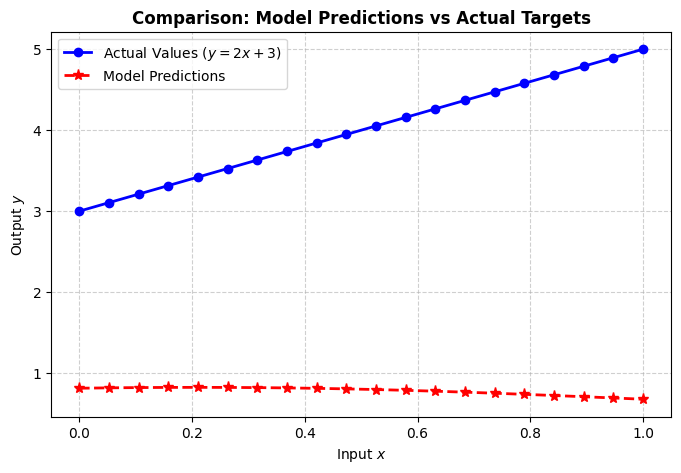

In [ ]:
import matplotlib.pyplot as plt

# Collect final predictions from the trained model
predicted_values = [p([inp]).value for inp in inputs]

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(x.numpy(), inity.numpy(), 'bo-', label='Actual Values ($y = 2x + 3$)', linewidth=2)
plt.plot(x.numpy(), predicts, 'r*--', label='Model Predictions', linewidth=2, markersize=8)

plt.title('Comparison: Model Predictions vs Actual Targets', fontsize=12, fontweight='bold')
plt.xlabel('Input $x$', fontsize=10)
plt.ylabel('Output $y$', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
p.parameters()

[Value is -0.5219984316453519,
 Value is 0.05991061428691746,
 Value is 0.5594447599278709,
 Value is -0.9176267781365324,
 Value is -0.9354252525511184,
 Value is 0.6576361910175483,
 Value is 0.5806049542192442,
 Value is -0.3828457456926375,
 Value is -0.8193862264981606,
 Value is -0.9846846057970664,
 Value is -0.16130810343451918,
 Value is 0.3803875137645394,
 Value is 0.14546460722038734,
 Value is -0.6836204628087745,
 Value is -0.6669737329510559,
 Value is 0.7485603316059302,
 Value is 0.5313520852968383,
 Value is 0.21538548607871388,
 Value is 0.4229210289599932,
 Value is -0.13559501124650875,
 Value is -0.36962709622862966,
 Value is -0.3020503472715028,
 Value is -0.057430680539878765,
 Value is -0.48414710501617453,
 Value is 0.05627613955918909,
 Value is -0.8084502644876093,
 Value is 0.08929735911424741,
 Value is -0.3920249250812817,
 Value is 0.18851679146449962,
 Value is 0.7177361098492376,
 Value is -0.6277796849825092,
 Value is -0.18301254692376667,
 Value is

In [ ]:
learning_rate = 0.01
epochs = 1000

# Prepare inputs as Instance objects
inputs = [Instance(val.item()) for val in x]
target_y = [Instance(val.item() if hasattr(val, 'item') else float(val)) for val in (2 * x + 3)]

for epoch in range(epochs):
    # --- Step 1: Forward Pass (Evaluate per input sample in MLP) ---
    preds = [p([inp]) for inp in inputs]

    # Compute Mean Squared Error Loss
    loss = sum(((pred - target)**2 for pred, target in zip(preds, target_y)), Instance(0.0))

    # --- Step 2: Zero Gradients ---
    p.zero_grad()

    # --- Step 3: Backward Pass ---
    loss._backwards()

    # --- Step 4: Parameter Update (Gradient Descent) ---
    for param in p.parameters():
        param.value -= learning_rate * param.grad

    # --- Logging ---
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.value:.4f}")

Epoch [10/1000], Loss: 7.3181
Epoch [20/1000], Loss: 5.6117
Epoch [30/1000], Loss: 1.4827
Epoch [40/1000], Loss: 4.0613
Epoch [50/1000], Loss: 14.7464
Epoch [60/1000], Loss: 1.3383
Epoch [70/1000], Loss: 1.8986
Epoch [80/1000], Loss: 1.2497
Epoch [90/1000], Loss: 0.5617
Epoch [100/1000], Loss: 0.3728
Epoch [110/1000], Loss: 0.3276
Epoch [120/1000], Loss: 0.3336
Epoch [130/1000], Loss: 0.3515
Epoch [140/1000], Loss: 0.3515
Epoch [150/1000], Loss: 0.3238
Epoch [160/1000], Loss: 0.2812
Epoch [170/1000], Loss: 0.2403
Epoch [180/1000], Loss: 0.2089
Epoch [190/1000], Loss: 0.1880
Epoch [200/1000], Loss: 0.1760
Epoch [210/1000], Loss: 0.1710
Epoch [220/1000], Loss: 0.1712
Epoch [230/1000], Loss: 0.1749
Epoch [240/1000], Loss: 0.1801
Epoch [250/1000], Loss: 0.1846
Epoch [260/1000], Loss: 0.1865
Epoch [270/1000], Loss: 0.1847
Epoch [280/1000], Loss: 0.1795
Epoch [290/1000], Loss: 0.1720
Epoch [300/1000], Loss: 0.1637
Epoch [310/1000], Loss: 0.1559
Epoch [320/1000], Loss: 0.1494
Epoch [330/1000]

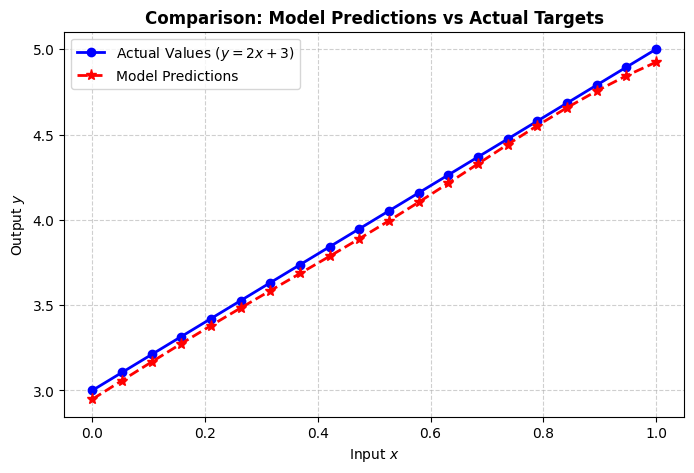

In [ ]:
import matplotlib.pyplot as plt
target_y = torch.tensor([t.value for t in target_y])
# Collect final predictions from the trained model
predicted_values = [p([inp]).value for inp in inputs]

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(x.numpy(), target_y.numpy(), 'bo-', label='Actual Values ($y = 2x + 3$)', linewidth=2)
plt.plot(x.numpy(), predicted_values, 'r*--', label='Model Predictions', linewidth=2, markersize=8)

plt.title('Comparison: Model Predictions vs Actual Targets', fontsize=12, fontweight='bold')
plt.xlabel('Input $x$', fontsize=10)
plt.ylabel('Output $y$', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Reinitialized existing Git repository in /content/.git/
mv: cannot stat 'Neural_Nets_01.ipynb': No such file or directory
mv: cannot stat 'First.ipynb': No such file or directory
mv: cannot stat 'Second.ipynb': No such file or directory
mv: cannot stat 'Third.ipynb': No such file or directory
On branch master
nothing to commit, working tree clean
